In [2]:
from typing import TypedDict, Annotated
from langgraph.graph import START, END, StateGraph
from langchain_openai import ChatOpenAI
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages import HumanMessage, BaseMessage

In [3]:
from langgraph.graph.message import add_messages
from dotenv import load_dotenv
load_dotenv()

True

In [4]:
import os
model = ChatOpenAI(
  model_name='gpt-4o',
  api_key=os.environ.get('OPENAI_API_KEY')
)

In [5]:
class keepState(TypedDict):
  topic: str
  joke: str
  explain: str

In [6]:
def joke_topic(state: keepState)-> keepState:
  topic = state['topic']
  response = model.invoke(f'Generate me a joke on the {topic}')
  return {'joke':response}

In [7]:
def joke_exp(state: keepState) -> keepState:
  joke = state['joke']
  response = model.invoke(f'Generate me an explanation of this {joke}')
  return {'explain':response}

In [8]:
graph = StateGraph(keepState)

graph.add_node('joke_topic',joke_topic)
graph.add_node('joke_exp',joke_exp)
graph.add_edge(START, 'joke_topic')
graph.add_edge('joke_topic','joke_exp')
graph.add_edge('joke_exp',END)

checkpointer = InMemorySaver()
workflow= graph.compile(checkpointer=checkpointer)

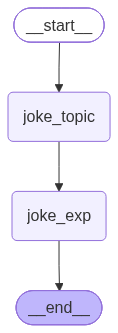

In [9]:
workflow

In [10]:
config1 = {'configurable': {'thread_id':'1'}}

workflow.invoke({'topic':'biryani'},config=config1)

{'topic': 'biryani',
 'joke': AIMessage(content="Why don't secrets last long at a biryani party?\n\nBecause the aroma of the biryani always spills the beans!", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 25, 'prompt_tokens': 16, 'total_tokens': 41, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-2024-08-06', 'system_fingerprint': 'fp_e85bcce457', 'id': 'chatcmpl-EZyatXgg9crCKMVvbQLSxBgckh18D', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a14a03-8cb6-7e63-bb29-dd049cee149c-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 16, 'output_tokens': 25, 'total_tokens': 41, 'input_token_de

In [12]:
config2 = {'configurable': {'thread_id':'2'}}

workflow.invoke({'topic':'pizza'},config=config2)

{'topic': 'pizza',
 'joke': AIMessage(content="Why did the pizza go to the party?\n\nBecause it couldn't resist a little slice of the action!", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 20, 'prompt_tokens': 14, 'total_tokens': 34, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-2024-08-06', 'system_fingerprint': 'fp_e85bcce457', 'id': 'chatcmpl-EZyfoZLSmbA7NSn3opt0f3cgxKEuy', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a14a08-3502-7d63-9064-4c4950f70be2-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 14, 'output_tokens': 20, 'total_tokens': 34, 'input_token_details': {'audio'

In [11]:
workflow.get_state(config1)

StateSnapshot(values={'topic': 'biryani', 'joke': AIMessage(content="Why don't secrets last long at a biryani party?\n\nBecause the aroma of the biryani always spills the beans!", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 25, 'prompt_tokens': 16, 'total_tokens': 41, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-2024-08-06', 'system_fingerprint': 'fp_e85bcce457', 'id': 'chatcmpl-EZyatXgg9crCKMVvbQLSxBgckh18D', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a14a03-8cb6-7e63-bb29-dd049cee149c-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 16, 'output_tokens': 25, 'total_tokens':

In [16]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'biryani', 'joke': AIMessage(content="Why don't secrets last long at a biryani party?\n\nBecause the aroma of the biryani always spills the beans!", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 25, 'prompt_tokens': 16, 'total_tokens': 41, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-2024-08-06', 'system_fingerprint': 'fp_e85bcce457', 'id': 'chatcmpl-EZyatXgg9crCKMVvbQLSxBgckh18D', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a14a03-8cb6-7e63-bb29-dd049cee149c-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 16, 'output_tokens': 25, 'total_tokens'

In [13]:
workflow.get_state(config2)

StateSnapshot(values={'topic': 'pizza', 'joke': AIMessage(content="Why did the pizza go to the party?\n\nBecause it couldn't resist a little slice of the action!", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 20, 'prompt_tokens': 14, 'total_tokens': 34, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-2024-08-06', 'system_fingerprint': 'fp_e85bcce457', 'id': 'chatcmpl-EZyfoZLSmbA7NSn3opt0f3cgxKEuy', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a14a08-3502-7d63-9064-4c4950f70be2-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 14, 'output_tokens': 20, 'total_tokens': 34, 'input_toke